Titanic - Machine Learning from Disaster

https://www.kaggle.com/competitions/titanic/overview

The sinking of the Titanic is one of the most infamous shipwrecks in history.

On April 15, 1912, during her maiden voyage, the widely considered “unsinkable” RMS Titanic sank after colliding with an iceberg. Unfortunately, there weren’t enough lifeboats for everyone onboard, resulting in the death of 1502 out of 2224 passengers and crew.

While there was some element of luck involved in surviving, it seems some groups of people were more likely to survive than others.

In this challenge, we ask you to build a predictive model that answers the question: “what sorts of people were more likely to survive?” using passenger data (ie name, age, gender, socio-economic class, etc).

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

In [2]:
df = pd.read_csv("titanic_train.csv")
df.shape

(891, 12)

In [3]:
df.head()

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


In [4]:
df.drop(["PassengerId", "Name", "Ticket"], axis=1, inplace=True)
df.head()

,Survived,Pclass,Sex,Age,SibSp,Parch,Fare,Cabin,Embarked
0,0,3,male,22.0,1,0,7.2500,NaN,S
1,1,1,female,38.0,1,0,71.2833,C85,C
2,1,3,female,26.0,0,0,7.9250,NaN,S
3,1,1,female,35.0,1,0,53.1000,C123,S
4,0,3,male,35.0,0,0,8.0500,NaN,S


In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 9 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   Survived  891 non-null    int64  
 1   Pclass    891 non-null    int64  
 2   Sex       891 non-null    object 
 3   Age       714 non-null    float64
 4   SibSp     891 non-null    int64  
 5   Parch     891 non-null    int64  
 6   Fare      891 non-null    float64
 7   Cabin     204 non-null    object 
 8   Embarked  889 non-null    object 
dtypes: float64(2), int64(4), object(3)
memory usage: 62.8+ KB


# Filling Missing Values

| % Values Missing | Regression |
|-----------|------------|
| ~2%       | Median (numeric) / Mode (categorical) imputation |  |
| ~20%      | Median imputation |
| ~50%      | Median + Missing Indicator |
| ~80%      | Drop feature (default) |
| ~97%      | Always drop |


In [6]:
df['Age'] = df['Age'].fillna(df['Age'].median()).astype(int)
df['Fare'] = df['Fare'].astype(float).round(1)

In [7]:
print(df['Embarked'].describe())
print(df['Embarked'].value_counts()/len(df))

count     889
unique      3
top         S
freq      644
Name: Embarked, dtype: object
Embarked
S    0.722783
C    0.188552
Q    0.086420
Name: count, dtype: float64


In [8]:
df['Embarked'] = df['Embarked'].map({'S': 0, 'C': 1, 'Q': 2})
df['Embarked'] = df['Embarked'].fillna(df['Embarked'].mode()[0]).astype(int)
# print(df['Embarked'].describe())
print(df['Embarked'].value_counts()/len(df))

Embarked
0    0.725028
1    0.188552
2    0.086420
Name: count, dtype: float64


In [9]:
print(df['Cabin'].describe())
print(df['Cabin'].isnull().sum() / len(df))

count         204
unique        147
top       B96 B98
freq            4
Name: Cabin, dtype: object
0.7710437710437711


Since 77% of values of 'Cabin' column are missing, we can either drop the column, or add a new indicative column of missing values, or assign a new value to missing values

In [10]:
df['Cabin'] = df['Cabin'].fillna('H').str[0].map({'A': 0, 'B': 1, 'C': 2, 'D': 3, 'E': 4, 'F': 5, 'G': 6, 'T': 7, 'H': 8})
print(df['Cabin'].describe())

count    891.000000
mean       6.716049
std        2.460739
min        0.000000
25%        8.000000
50%        8.000000
75%        8.000000
max        8.000000
Name: Cabin, dtype: float64


In [11]:
df['Sex'] = df['Sex'].map({'male': 1, 'female': 0})
df['Pclass'] = df['Pclass'].map({1: 0, 2: 1, 3: 2})
df.head()

,Survived,Pclass,Sex,Age,SibSp,Parch,Fare,Cabin,Embarked
0,0,2,1,22,1,0,7.2,8,0
1,1,0,0,38,1,0,71.3,2,1
2,1,2,0,26,0,0,7.9,8,0
3,1,0,0,35,1,0,53.1,2,0
4,0,2,1,35,0,0,8.0,8,0


In [12]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 9 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   Survived  891 non-null    int64  
 1   Pclass    891 non-null    int64  
 2   Sex       891 non-null    int64  
 3   Age       891 non-null    int32  
 4   SibSp     891 non-null    int64  
 5   Parch     891 non-null    int64  
 6   Fare      891 non-null    float64
 7   Cabin     891 non-null    int64  
 8   Embarked  891 non-null    int32  
dtypes: float64(1), int32(2), int64(6)
memory usage: 55.8 KB


In [13]:
df.describe()

,Survived,Pclass,Sex,Age,SibSp,Parch,Fare,Cabin,Embarked
count,891.000000,891.000000,891.000000,891.000000,891.000000,891.000000,891.000000,891.000000,891.000000
mean,0.383838,1.308642,0.647587,29.345679,0.523008,0.381594,32.205724,6.716049,0.361392
std,0.486592,0.836071,0.477990,13.028212,1.102743,0.806057,49.693523,2.460739,0.635673
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,0.000000,1.000000,0.000000,22.000000,0.000000,0.000000,7.900000,8.000000,0.000000
50%,0.000000,2.000000,1.000000,28.000000,0.000000,0.000000,14.500000,8.000000,0.000000
75%,1.000000,2.000000,1.000000,35.000000,1.000000,0.000000,31.000000,8.000000,1.000000
max,1.000000,2.000000,1.000000,80.000000,8.000000,6.000000,512.300000,8.000000,2.000000


array([[<Axes: title={'center': 'Survived'}>,
        <Axes: title={'center': 'Pclass'}>,
        <Axes: title={'center': 'Sex'}>],
       [<Axes: title={'center': 'Age'}>,
        <Axes: title={'center': 'SibSp'}>,
        <Axes: title={'center': 'Parch'}>],
       [<Axes: title={'center': 'Fare'}>,
        <Axes: title={'center': 'Cabin'}>,
        <Axes: title={'center': 'Embarked'}>]], dtype=object)

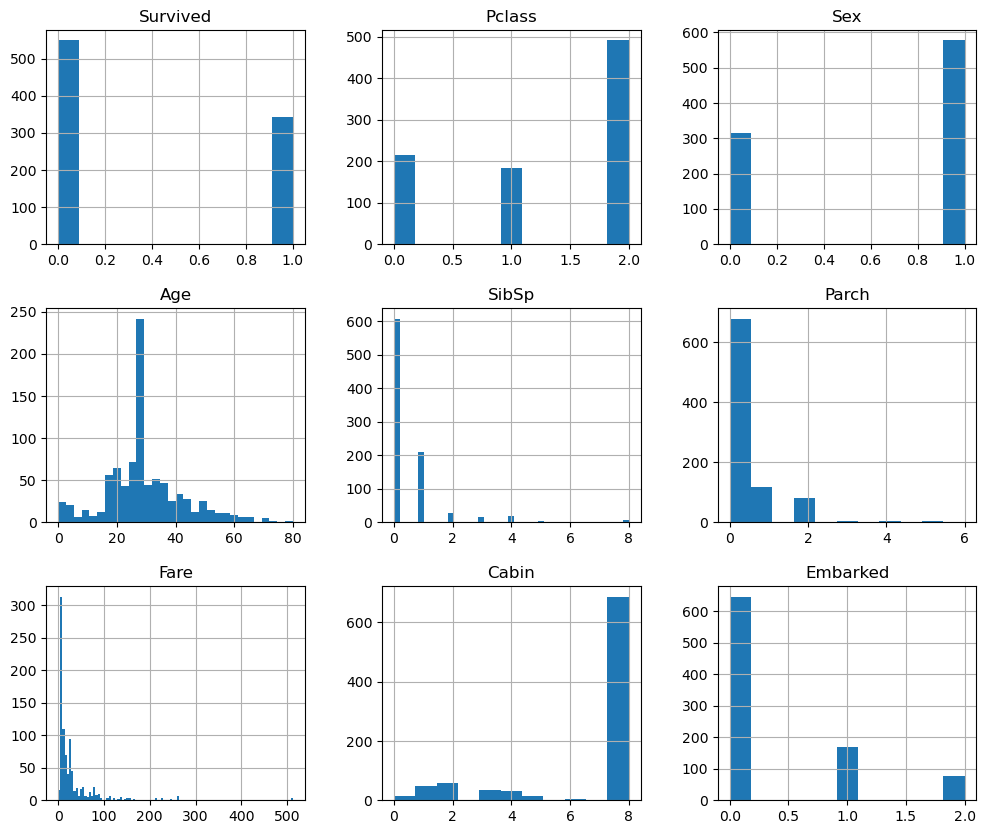

In [14]:
df.select_dtypes(include='number').hist(bins='auto', figsize=(12,10))

   Survived  Pclass  Sex       Age  SibSp  Parch      Fare  Cabin  Embarked
0         0       2    1 -0.564145      1      0 -0.503481      8         0
1         1       0    0  0.664649      1      0  0.787150      2         1
2         1       2    0 -0.256947      0      0 -0.489387      8         0
3         1       0    0  0.434250      1      0  0.420699      2         0
4         0       2    1  0.434250      0      0 -0.487374      8         0


array([[<Axes: title={'center': 'Survived'}>,
        <Axes: title={'center': 'Pclass'}>,
        <Axes: title={'center': 'Sex'}>],
       [<Axes: title={'center': 'Age'}>,
        <Axes: title={'center': 'SibSp'}>,
        <Axes: title={'center': 'Parch'}>],
       [<Axes: title={'center': 'Fare'}>,
        <Axes: title={'center': 'Cabin'}>,
        <Axes: title={'center': 'Embarked'}>]], dtype=object)

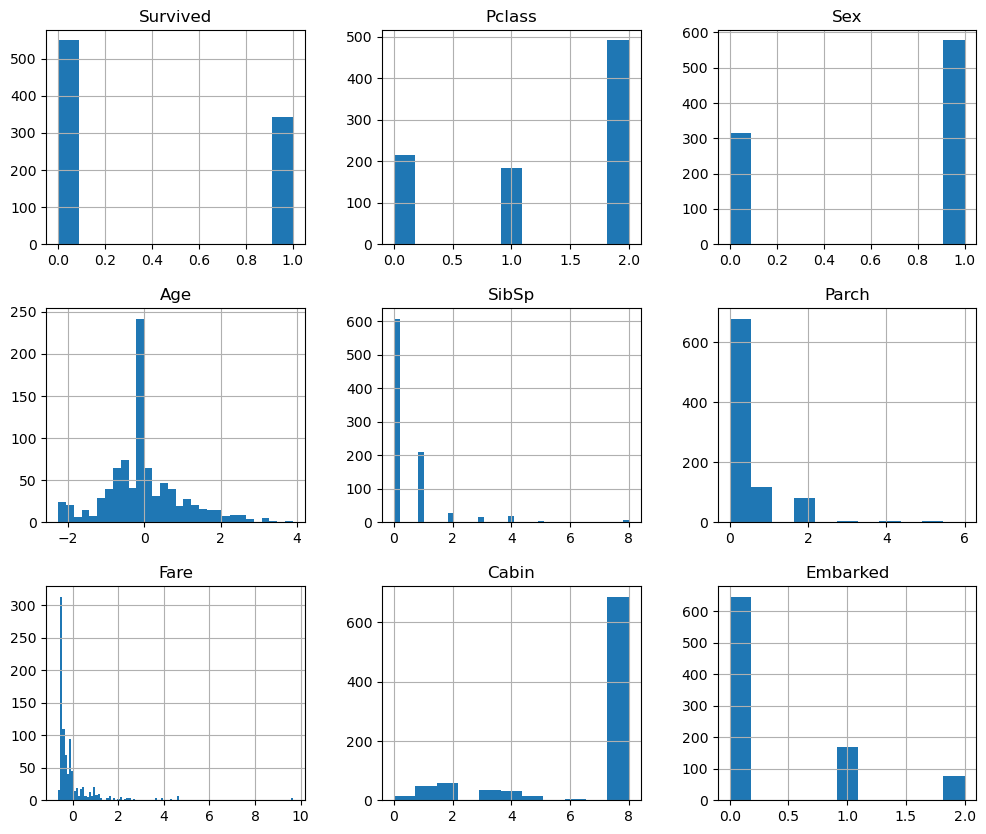

In [15]:
# z-score normalization
from sklearn.preprocessing import StandardScaler

# Specify the columns to scale
cols_to_scale = ['Age', 'Fare']

scaler = StandardScaler()

# Fit on df columns and transform
df[cols_to_scale] = scaler.fit_transform(df[cols_to_scale])

print(df.head())
df.select_dtypes(include='number').hist(bins='auto', figsize=(12,10))

In [16]:
from sklearn.model_selection import train_test_split

X = df.drop('Survived', axis=1)
Y = df['Survived']

X_train, X_test, Y_train, Y_test = train_test_split(X, Y, train_size=0.8, random_state=41)

print(X_train.shape, X_test.shape)
print(Y_train.shape, Y_test.shape)

(712, 8) (179, 8)
(712,) (179,)


# Classical ML mistake made here !!!!!

# Data Leakage

Data leakage happens when training data is contaminated with future or test-set information, often through preprocessing or feature engineering done before splitting. This causes inflated evaluation metrics and poor real-world performance.   

Never do preprocessing (fill missing values with whole df median, normalize with whole df values) before train-test split.  
If we do preprocessing before split, we are seeing test set values, thier median unknowingly.
Test (Cross Validation) set MUST remain unseen/untouched.

Leakage Types :-

1. Scaling leakage  -  while normalizing, we have to use training set's mean and std, NOT whole df's mean and std.  
For normalizing test set also, use training set's values.
2. Median leakage (30% missing)	- while filling missing values in the columns, we have to fill by training set's median values.  
For filling test set also, use training set's values.
3. Target leakage  - Occurs when when target information leaks into features. e.g. predicting patient will survive or not using feature like, "level of     treatment given" or "on ventilator". These features literally contains the answer.
4. Time-series leakage  - Time-series shuffling future into past. See past, predict future, dont shuffle.

# So we will start again from beginning of importing dataset

In [17]:
df = pd.read_csv("titanic_train.csv")
df.drop(["PassengerId", "Name", "Ticket"], axis=1, inplace=True)
df['Embarked'] = df['Embarked'].map({'S': 0, 'C': 1, 'Q': 2})
df['Cabin'] = df['Cabin'].fillna('H').str[0].map({'A': 0, 'B': 1, 'C': 2, 'D': 3, 'E': 4, 'F': 5, 'G': 6, 'T': 7, 'H': 8})
df['Sex'] = df['Sex'].map({'male': 1, 'female': 0})
df['Pclass'] = df['Pclass'].map({1: 0, 2: 1, 3: 2})
df['Fare'] = df['Fare'].astype(float).round(1)
df.info()

# df['Age'] = df['Age'].fillna(df['Age'].median()).astype(int)

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 9 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   Survived  891 non-null    int64  
 1   Pclass    891 non-null    int64  
 2   Sex       891 non-null    int64  
 3   Age       714 non-null    float64
 4   SibSp     891 non-null    int64  
 5   Parch     891 non-null    int64  
 6   Fare      891 non-null    float64
 7   Cabin     891 non-null    int64  
 8   Embarked  889 non-null    float64
dtypes: float64(3), int64(6)
memory usage: 62.8 KB


Few cells of Age and Embarked columns are missing.  
So, we have to split into train-test set first and then apply pre-processing on them acc to training set values.

In [18]:
df.head()

,Survived,Pclass,Sex,Age,SibSp,Parch,Fare,Cabin,Embarked
0,0,2,1,22.0,1,0,7.2,8,0.0
1,1,0,0,38.0,1,0,71.3,2,1.0
2,1,2,0,26.0,0,0,7.9,8,0.0
3,1,0,0,35.0,1,0,53.1,2,0.0
4,0,2,1,35.0,0,0,8.0,8,0.0


In [19]:
from sklearn.model_selection import train_test_split

X = df.drop('Survived', axis=1)
Y = df['Survived']

X_train, X_test, Y_train, Y_test = train_test_split(X, Y, train_size=0.8, random_state=42)

print(X_train.shape, X_test.shape)
print(Y_train.shape, Y_test.shape)

(712, 8) (179, 8)
(712,) (179,)


sklearn also does preprocessing with its pipeline and Columntransformers syntaxes. Here we are doing manual preprocessing.  
# Preprocessing rule
Imputation first (fill missing values), then normalization

In [20]:
# Imputation
age_median = X_train['Age'].median()
X_train['Age'] = X_train['Age'].fillna(age_median)
X_test['Age'] = X_test['Age'].fillna(age_median)

embarked_mode = X_train['Embarked'].mode()[0]
X_train['Embarked'] = X_train['Embarked'].fillna(embarked_mode)
X_test['Embarked'] = X_test['Embarked'].fillna(embarked_mode)
X_train['Embarked'] = X_train['Embarked'].astype(int)
X_test['Embarked'] = X_test['Embarked'].astype(int)

# Scaling
scaler = StandardScaler() # Z-score normalizattion
scaler.fit(X_train[['Age', 'Fare']])

X_train[['Age', 'Fare']] = scaler.transform(X_train[['Age', 'Fare']])
X_test[['Age', 'Fare']] = scaler.transform(X_test[['Age', 'Fare']])


print(X_train.head())


     Pclass  Sex       Age  SibSp  Parch      Fare  Cabin  Embarked
331       0    1  1.253641      0      0 -0.078710      2         0
733       1    1 -0.477284      0      0 -0.377174      8         0
382       2    1  0.215086      0      0 -0.475378      8         0
704       2    1 -0.246494      1      0 -0.475378      8         0
813       2    0 -1.785093      4      2 -0.024794      8         0


In [21]:
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.svm import SVC
from sklearn.naive_bayes import GaussianNB

from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, roc_auc_score
)

models = {
    "Logistic Regression": LogisticRegression(max_iter=1000),
    "KNN": KNeighborsClassifier(),
    "Decision Tree": DecisionTreeClassifier(random_state=42),
    "Random Forest": RandomForestClassifier(random_state=42),
    "Gradient Boosting": GradientBoostingClassifier(random_state=42),
    "SVM": SVC(probability=True),
    "Naive Bayes": GaussianNB()
}

In [22]:
results = []

for name, model in models.items():

    # 1. Fit model
    model.fit(X_train, Y_train)

    # 2. Predict labels
    Y_pred = model.predict(X_test)

    # 3. Predict probabilities (if available)
    if hasattr(model, "predict_proba"):
        # print(name)
        y_prob = model.predict_proba(X_test)[:, 1]
        roc = roc_auc_score(Y_test, y_prob)
    else:
        roc = np.nan

    # 4. Store results
    results.append({
        "Model": name,
        "Accuracy": accuracy_score(Y_test, Y_pred),
        "Precision": precision_score(Y_test, Y_pred),
        "Recall": recall_score(Y_test, Y_pred),
        "F1": f1_score(Y_test, Y_pred),
        "ROC-AUC": roc
    })


In [23]:
results_df = pd.DataFrame(results).sort_values(by="F1", ascending=False)
results_df


,Model,Accuracy,Precision,Recall,F1,ROC-AUC
0,Logistic Regression,0.815642,0.788732,0.756757,0.772414,0.881982
4,Gradient Boosting,0.815642,0.797101,0.743243,0.769231,0.867954
1,KNN,0.804469,0.774648,0.743243,0.758621,0.846139
3,Random Forest,0.798883,0.779412,0.716216,0.746479,0.883205
6,Naive Bayes,0.776536,0.707317,0.783784,0.743590,0.852381
5,SVM,0.787709,0.764706,0.702703,0.732394,0.876190
2,Decision Tree,0.759777,0.706667,0.716216,0.711409,0.759846
